In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.max_columns",None)
DATA_PATH = "../data/processed/bank_clean.csv"

In [2]:
df = pd.read_csv(DATA_PATH)
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,ZeroBalance,ProductGroup,AgeBand,TenureBand,CreditBand,BalanceBand
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,1,40-49,0-2,Fair,Zero
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,0,1,40-49,0-2,Fair,Low
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,0,3+,40-49,6-8,Poor,High
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,1,2,30-39,0-2,Good,Zero
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,1,40-49,0-2,Very Good+,Mid


In [3]:
from scipy import stats

orders = {
    "AgeBand" :    ["18-29","30-39","40-49","50-59","60+"],
    "TenureBand" : ["0-2","3-5","6-8","9-10"],
    "CreditBand" : ["Poor","Fair","Good","Very Good+"],
    "BalanceBand" :["Zero","Low","Mid","High"],
    "ProductGroup" : ["1","2","3+"]
}

df = pd.read_csv(DATA_PATH, keep_default_na=False)
df["ProductGroup"] = df["ProductGroup"].astype(str)
for col, cats in orders.items():
    df[col] = pd.Categorical(df[col], categories=cats, ordered=True)

print(df.shape)
print(df[list(orders)].dtypes)
print(df[list(orders)].isna().sum())
print("Overall churn:", df["Exited"].mean().round(4))

(10000, 17)
AgeBand         category
TenureBand      category
CreditBand      category
BalanceBand     category
ProductGroup    category
dtype: object
AgeBand         0
TenureBand      0
CreditBand      0
BalanceBand     0
ProductGroup    0
dtype: int64
Overall churn: 0.2037


In [4]:
overall = df["Exited"].mean()         
total_churned = df["Exited"].sum()     

def churn_by(col):
    # customers = rows per group, churned = sum of Exited per group
    g = df.groupby(col, observed=True)["Exited"].agg(customers="count", churned="sum")
    g["churn_rate"] = (g["churned"] / g["customers"]).round(4)
    g["share_of_churners"] = (g["churned"] / total_churned).round(4)
    g["lift"] = (g["churn_rate"] / overall).round(2)
    return g

churn_by("AgeBand")

,customers,churned,churn_rate,share_of_churners,lift
AgeBand,,,,,
18-29,1641,124,0.0756,0.0609,0.37
30-39,4346,473,0.1088,0.2322,0.53
40-49,2618,806,0.3079,0.3957,1.51
50-59,869,487,0.5604,0.2391,2.75
60+,526,147,0.2795,0.0722,1.37


In [5]:
cols = ["Geography","Gender","AgeBand","TenureBand","CreditBand","BalanceBand",
       "BalanceBand","ProductGroup","HasCrCard","IsActiveMember"]
for c in cols:
    print(f"\n----- {c} -----")
    display(churn_by(c))


----- Geography -----


,customers,churned,churn_rate,share_of_churners,lift
Geography,,,,,
France,5014,810,0.1615,0.3976,0.79
Germany,2509,814,0.3244,0.3996,1.59
Spain,2477,413,0.1667,0.2027,0.82



----- Gender -----


,customers,churned,churn_rate,share_of_churners,lift
Gender,,,,,
Female,4543,1139,0.2507,0.5592,1.23
Male,5457,898,0.1646,0.4408,0.81



----- AgeBand -----


,customers,churned,churn_rate,share_of_churners,lift
AgeBand,,,,,
18-29,1641,124,0.0756,0.0609,0.37
30-39,4346,473,0.1088,0.2322,0.53
40-49,2618,806,0.3079,0.3957,1.51
50-59,869,487,0.5604,0.2391,2.75
60+,526,147,0.2795,0.0722,1.37


... (10 outputs left out)


----- HasCrCard -----


,customers,churned,churn_rate,share_of_churners,lift
HasCrCard,,,,,
0,2945,613,0.2081,0.3009,1.02
1,7055,1424,0.2018,0.6991,0.99



----- IsActiveMember -----


,customers,churned,churn_rate,share_of_churners,lift
IsActiveMember,,,,,
0,4849,1302,0.2685,0.6392,1.32
1,5151,735,0.1427,0.3608,0.70



=== Geography X Gender: churn rate === 


Gender,Female,Male
Geography,,
France,0.2034,0.1271
Germany,0.3755,0.2781
Spain,0.2121,0.1311



--- Geography X Gender: customer counts ---


Gender,Female,Male
Geography,,
France,2261,2753
Germany,1193,1316
Spain,1089,1388


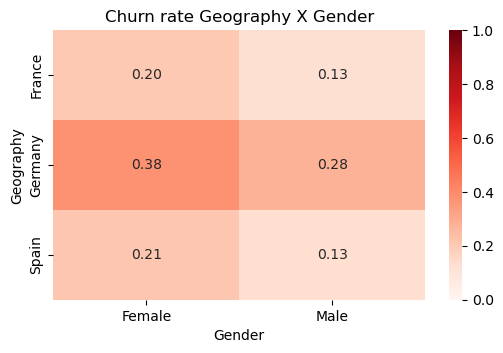


=== AgeBand X ProductGroup: churn rate === 


ProductGroup,1,2,3+
AgeBand,,,
18-29,0.1086,0.0291,0.6296
30-39,0.1520,0.0421,0.7500
40-49,0.4010,0.1179,0.9187
50-59,0.6406,0.2852,0.9855
60+,0.3474,0.1330,0.8261



--- AgeBand X ProductGroup: customer counts ---


ProductGroup,1,2,3+
AgeBand,,,
18-29,755,859,27
30-39,2098,2164,84
40-49,1409,1086,123
50-59,537,263,69
60+,285,218,23


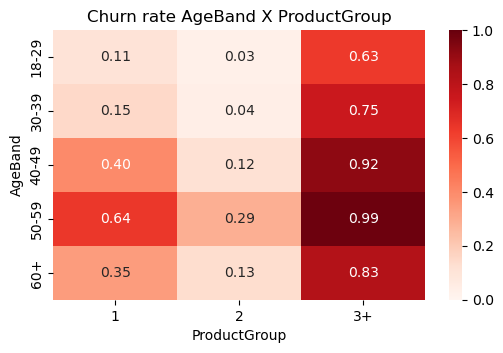


=== IsActiveMember X ProductGroup: churn rate === 


ProductGroup,1,2,3+
IsActiveMember,,,
0,0.3665,0.0989,0.9022
1,0.1892,0.0556,0.8028



--- IsActiveMember X ProductGroup: customer counts ---


ProductGroup,1,2,3+
IsActiveMember,,,
0,2521,2144,184
1,2563,2446,142


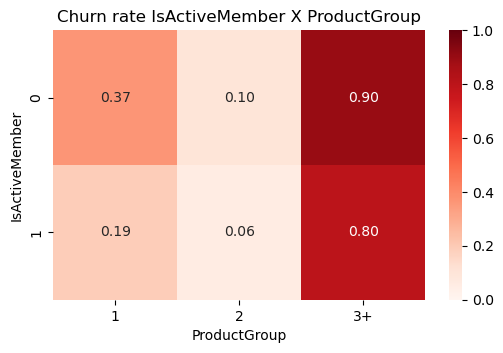


=== Geography X BalanceBand: churn rate === 


BalanceBand,Zero,Low,Mid,High
Geography,,,,
France,0.1394,0.1808,0.1572,0.2055
Germany,NaN,0.2548,0.4210,0.2777
Spain,0.1359,0.2129,0.1671,0.2032



--- Geography X BalanceBand: customer counts ---


BalanceBand,Zero,Low,Mid,High
Geography,,,,
France,2418.0,896.0,795.0,905.0
Germany,NaN,781.0,943.0,785.0
Spain,1199.0,451.0,389.0,438.0


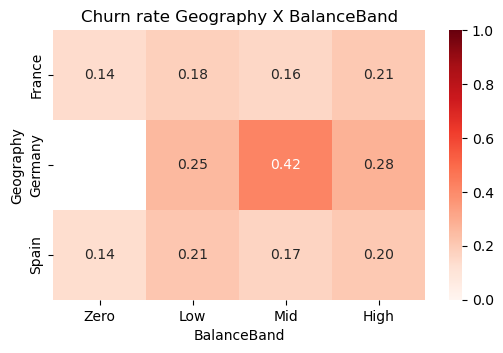


=== AgeBand X IsActiveMember: churn rate === 


IsActiveMember,0,1
AgeBand,,
18-29,0.0983,0.0538
30-39,0.1363,0.0816
40-49,0.3797,0.2259
50-59,0.8123,0.3710
60+,0.8559,0.1253



--- AgeBand X IsActiveMember: customer counts ---


IsActiveMember,0,1
AgeBand,,
18-29,804,837
30-39,2165,2181
40-49,1396,1222
50-59,373,496
60+,111,415


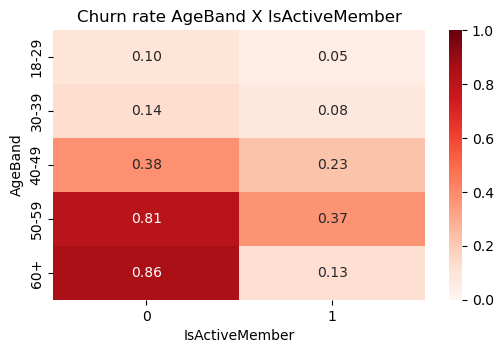

In [6]:
def churn_pivot(r,c):
    # Churn rate for every combination of the two columns
    rate = df.pivot_table(index=r, columns=c, values="Exited",
                         aggfunc="mean", observed=True).round(4)
    # customer counts per combination 
    n = df.pivot_table(index=r, columns=c, values="Exited",
                      aggfunc="count", observed=True)
    return rate, n

pairs = [
    ("Geography","Gender"),
    ("AgeBand","ProductGroup"),
    ("IsActiveMember","ProductGroup"),
    ("Geography","BalanceBand"),
    ("AgeBand","IsActiveMember")
]
for r, c in pairs:
    rate, n = churn_pivot(r,c)
    print(f"\n=== {r} X {c}: churn rate === ")
    display(rate)
    print(f"\n--- {r} X {c}: customer counts ---")
    display(n)
    plt.figure(figsize=(6,3.5))
    sns.heatmap(rate, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1)
    plt.title(f"Churn rate {r} X {c}")
    plt.show()

In [7]:
cat_cols = ["Geography", "Gender", "AgeBand", "TenureBand", "CreditBand",
            "BalanceBand", "ProductGroup", "HasCrCard", "IsActiveMember"]
rows = []
for c in cat_cols:
    table = pd.crosstab(df[c], df["Exited"])
    chi2, p, dof, expected = stats.chi2_contingency(table)
    n = table.values.sum()
    v = np.sqrt(chi2/(n*(min(table.shape)-1)))
    rows.append({"feature":c, "chi2": round(chi2,1), "p_value":p, "cramers_v": round(v,4)})
chi_results = pd.DataFrame(rows).sort_values("cramers_v", ascending=False).reset_index(drop=True)
chi_results.style.format({"p_value": "{:.2e}"})

,feature,chi2,p_value,cramers_v
0,ProductGroup,1494.600000,0.00e+00,0.386600
1,AgeBand,1282.700000,1.90e-276,0.358100
2,Geography,301.300000,3.83e-66,0.173600
3,IsActiveMember,243.000000,8.79e-55,0.155900
4,BalanceBand,175.900000,6.67e-38,0.132600
5,Gender,112.900000,2.25e-26,0.106300
6,CreditBand,8.600000,3.44e-02,0.029400
7,TenureBand,6.200000,1.03e-01,0.024900
8,HasCrCard,0.500000,4.92e-01,0.006900


In [8]:
num_cols = ["Age","CreditScore","Balance","EstimatedSalary","Tenure"]

rows = []
for c in num_cols:
    a = df.loc[df["Exited"] == 1, c]
    b = df.loc[df["Exited"] == 0, c]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    rows.append({"feature":c, "median_churned": a.median(),
                "median_retained": b.median(), "p_value": p})
pd.DataFrame(rows).style.format({"p_value":"{:.2e}"})        

,feature,median_churned,median_retained,p_value
0,Age,45.000000,36.000000,3.21e-230
1,CreditScore,646.000000,653.000000,1.99e-02
2,Balance,109349.290000,92072.680000,1.12e-28
3,EstimatedSalary,102460.840000,99645.040000,2.27e-01
4,Tenure,5.000000,5.000000,1.62e-01


In [9]:
overall = df["Exited"].mean()
print(f"overall churn rate:{overall:.1%}\n")

top_feature = ["ProductGroup","AgeBand","Geography","IsActiveMember",
              "BalanceBand","Gender"]

for c in top_feature:
    t = (df.groupby(c, observed=True)["Exited"]
        .agg(customer="count", churned="sum", churn_rate="mean")
        .assign(vs_overall=lambda x: x["churn_rate"] - overall)
        .sort_values("churn_rate",ascending=False))
    display(t.style.format({"churn_rate": "{:.1%}", "vs_overall": "{:+.1%}"}))

overall churn rate:20.4%



,customer,churned,churn_rate,vs_overall
ProductGroup,,,,
3+,326,280,85.9%,+65.5%
1,5084,1409,27.7%,+7.3%
2,4590,348,7.6%,-12.8%


,customer,churned,churn_rate,vs_overall
AgeBand,,,,
50-59,869,487,56.0%,+35.7%
40-49,2618,806,30.8%,+10.4%
60+,526,147,27.9%,+7.6%
30-39,4346,473,10.9%,-9.5%
18-29,1641,124,7.6%,-12.8%


,customer,churned,churn_rate,vs_overall
Geography,,,,
Germany,2509,814,32.4%,+12.1%
Spain,2477,413,16.7%,-3.7%
France,5014,810,16.2%,-4.2%


,customer,churned,churn_rate,vs_overall
IsActiveMember,,,,
0,4849,1302,26.9%,+6.5%
1,5151,735,14.3%,-6.1%


,customer,churned,churn_rate,vs_overall
BalanceBand,,,,
Mid,2127,587,27.6%,+7.2%
High,2128,493,23.2%,+2.8%
Low,2128,457,21.5%,+1.1%
Zero,3617,500,13.8%,-6.5%


,customer,churned,churn_rate,vs_overall
Gender,,,,
Female,4543,1139,25.1%,+4.7%
Male,5457,898,16.5%,-3.9%


In [10]:
frames = []
for c in top_feature:
    t = (df.groupby(c, observed=True)["Exited"]
            .agg(customers="count", churn_rate="mean").reset_index()
            .rename(columns={c: "segment"}))
    t.insert(0, "feature",c)
    frames.append(t)

segments = pd.concat(frames).sort_values("churn_rate",ascending=False)
segments[segments["customers"]>= 200].head(10)

,feature,segment,customers,churn_rate
2,ProductGroup,3+,326,0.858896
3,AgeBand,50-59,869,0.560414
1,Geography,Germany,2509,0.324432
2,AgeBand,40-49,2618,0.307869
4,AgeBand,60+,526,0.279468
0,ProductGroup,1,5084,0.277144
2,BalanceBand,Mid,2127,0.275976
0,IsActiveMember,0,4849,0.268509
0,Gender,Female,4543,0.250715
3,BalanceBand,High,2128,0.231673


In [11]:
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score

df["ZeroBalance"] = (df["Balance"] == 0).astype(int)

formula = (
    "Exited ~ C(ProductGroup, Treatment('1'))"
    "+C(AgeBand, Treatment('30-39'))"
    " + C(Geography, Treatment('France'))"
    " + C(Gender, Treatment('Male'))"
    " + IsActiveMember + ZeroBalance"
)
model = smf.logit(formula, data=df).fit()

ci = model.conf_int()
or_table = pd.DataFrame({
    "odds_ratio": np.exp(model.params),
    "ci_low": np.exp(ci[0]),
    "ci_high": np.exp(ci[1]),
    "p_value": model.pvalues,
}).drop("Intercept")

or_table.index = (or_table.index
                  .str.replace(r"C\((\w+), Treatment\('.*?'\)\)\[T\.", r"\1: ", regex=True)
                  .str.replace("]","",regex=False))

display(or_table.sort_values("odds_ratio",ascending=False)
       .style.format({"odds_ratio":"{:.2f}", "p_value": "{:.2e}"}))

print(f"Pseudo R²: {model.prsquared:.3f}")
print(f"AUC: {roc_auc_score(df["Exited"], model.predict(df)):.3f}")

Optimization terminated successfully.
         Current function value: 0.359114
         Iterations 7


,odds_ratio,ci_low,ci_high,p_value
ProductGroup: 3+,16.23,11.452169,23.002878,2.68e-55
AgeBand: 50-59,11.78,9.729792,14.270412,1.24e-140
AgeBand: 60+,4.37,3.411369,5.604793,2.35e-31
AgeBand: 40-49,3.49,3.025636,4.017618,8.73e-67
Geography: Germany,2.61,2.247332,3.030454,2.83e-36
Gender: Female,1.71,1.523186,1.928542,3.53e-19
ZeroBalance,1.19,1.014651,1.385196,3.21e-02
Geography: Spain,1.05,0.898056,1.216519,5.68e-01
AgeBand: 18-29,0.66,0.526347,0.824870,2.73e-04
IsActiveMember,0.36,0.313612,0.401851,2.92e-60


Pseudo R²: 0.290
AUC: 0.844


In [12]:
pd.crosstab(df["Geography"], df["ZeroBalance"], normalize="index")

ZeroBalance,0,1
Geography,,
France,0.517750,0.482250
Germany,1.000000,0.000000
Spain,0.515947,0.484053


A multivariable logistic regression (pseudo R² = 0.29, AUC = 0.84) confirmed that product holding, age, geography and engagement independently predict churn. Customers with 3+ products and those aged 50-59 had the highest odds of churning, while holding exactly two products was the strongest protective factor. German customers and inactive members had roughly 2.6 and 2.8 times the odds of churning, respectively, after adjusting for other factors. Credit card ownership, tenure, salary and credit score showed little relationship with churn.

In [13]:
print(pd.crosstab(df["Geography"], df["ZeroBalance"]))

print(f"- - - - - - - - - - - - - - - - - - - -")

rates = df.pivot_table(index="Geography", columns="ZeroBalance",
                          values="Exited", aggfunc="mean").round(4)
print(rates)

print(f"- - - - - - - - - - - - - - - - - - - -")

counts = df.pivot_table(index="Geography", columns="ZeroBalance",
                           values="Exited", aggfunc="count")
print(counts)

ZeroBalance     0     1
Geography              
France       2596  2418
Germany      2509     0
Spain        1278  1199
- - - - - - - - - - - - - - - - - - - -
ZeroBalance       0       1
Geography                  
France       0.1822  0.1394
Germany      0.3244     NaN
Spain        0.1956  0.1359
- - - - - - - - - - - - - - - - - - - -
ZeroBalance       0       1
Geography                  
France       2596.0  2418.0
Germany      2509.0     NaN
Spain        1278.0  1199.0


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score, f1_score

X = pd.get_dummies(
    df[["ProductGroup", "AgeBand", "Geography", "Gender", "IsActiveMember", "ZeroBalance"]],
    drop_first = True
).astype(float)
y = df["Exited"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25,
                                         stratify=y, random_state=42)

model = LogisticRegression(max_iter=1000, class_weight="balanced").fit(X_tr, y_tr)

proba = model.predict_proba(X_te)[:, 1]
pred = model.predict(X_te)
print("Test AUC :",round(roc_auc_score(y_te, proba),4))
print("Recall   :",round(recall_score(y_te, pred),4))
print("F1       :",round(f1_score(y_te, pred),4))

Test AUC : 0.855
Recall   : 0.7564
F1       : 0.5751


In [15]:
ranking = pd.DataFrame({
    "Driver":["ProductGroup", "AgeBand", "Geography", "IsActiveMember",
               "BalanceBand", "Gender", "CreditBand", "TenureBand", "HasCrCard"],
    "CramersV":[0.387, 0.358, 0.174, 0.156, 0.133, 0.106, 0.029, 0.025, 0.007],
})
ranking["Strenght"] = pd.cut(ranking["CramersV"],[0, 0.05,0.15,0.30,1],
                                labels=["Negligible","Weak","Moderate","Strong"])
print(ranking.to_string(index=False))

        Driver  CramersV   Strenght
  ProductGroup     0.387     Strong
       AgeBand     0.358     Strong
     Geography     0.174   Moderate
IsActiveMember     0.156   Moderate
   BalanceBand     0.133       Weak
        Gender     0.106       Weak
    CreditBand     0.029 Negligible
    TenureBand     0.025 Negligible
     HasCrCard     0.007 Negligible
